In [ ]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
X = heart_disease.data.features
y = heart_disease.data.targets

# metadata
print(heart_disease.metadata)

# variable information
print(heart_disease.variables)


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

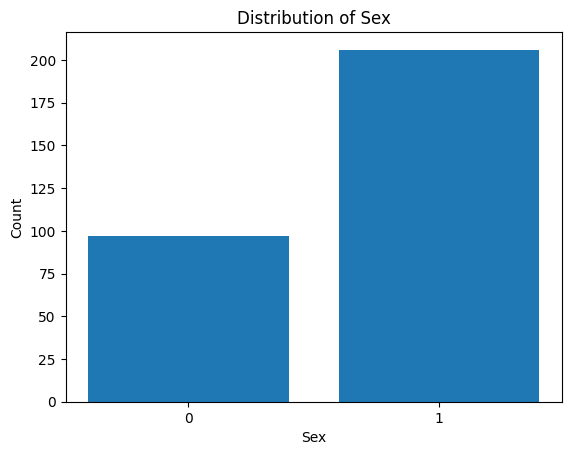

In [ ]:
import matplotlib.pyplot as plt

# Count occurrences of each category in "sex"
sex_counts = X["sex"].value_counts().sort_index()

# Create bar plot
plt.bar(sex_counts.index, sex_counts.values)

# Format x-axis to show only 0 and 1 without decimals
plt.xticks([0, 1], ["0", "1"])

# Labels and title
plt.xlabel("Sex")
plt.ylabel("Count")
plt.title("Distribution of Sex")

# Show plot
plt.show()

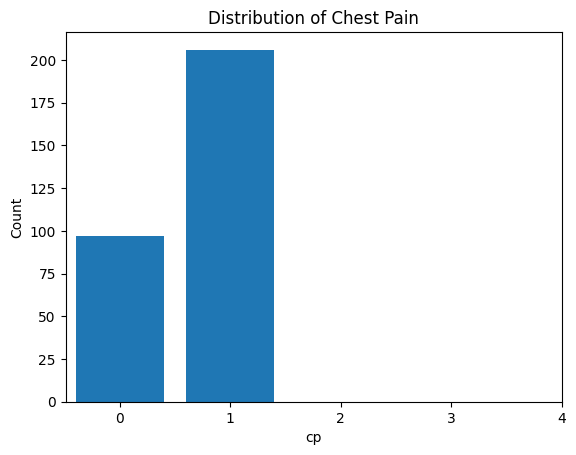

In [ ]:
import matplotlib.pyplot as plt

# Count occurrences of each category in "sex"
cp_counts = X["cp"].value_counts().sort_index()

# Create bar plot
plt.bar(sex_counts.index, sex_counts.values)

# Format x-axis to show only 0 and 1 without decimals
plt.xticks([0, 1, 2, 3, 4], ["0", "1", "2", "3", "4"])

# Labels and title
plt.xlabel("cp")
plt.ylabel("Count")
plt.title("Distribution of Chest Pain")

# Show plot
plt.show()

In [ ]:
X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0


In [ ]:
y

,num
0,0
1,2
2,1
3,0
4,0
...,...
298,1
299,2
300,3
301,1


In [ ]:
import numpy as np
X_no_nan = np.nan_to_num(X, nan=0)

In [ ]:
import imblearn
from imblearn.over_sampling import SMOTE
oversample = SMOTE()
X, y = oversample.fit_resample(X_no_nan, y)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)



In [ ]:
# Initialize and train the Logistic Regression model
clf = LogisticRegression(random_state=0, solver='lbfgs')
clf.fit(X_train, y_train)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(random_state=0)

In [ ]:
# Make predictions on the test set
y_pred = clf.predict(X_test)

In [ ]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

f1 = f1_score(y_test, y_pred, average='weighted')
print("F1 Score:", f1)

roc_auc_score(y_test, clf.predict_proba(X_test), multi_class='ovr')
AUC = roc_auc_score(y_test, clf.predict_proba(X_test), multi_class='ovr')
print("Area Under the Curve Score:", AUC)

recall = recall_score(y_test, y_pred, average="micro")
#print("Recall:", recall)

precision = precision_score(y_test, y_pred, average="weighted")
#print("Precision:", precision)

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()

plt.show()

Accuracy: 0.4878048780487805
F1 Score: 0.4804109561293644


NameError: name 'roc_auc_score' is not defined

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
neigh = KNeighborsClassifier(n_neighbors=2)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
neigh.fit(X_train, y_train)

#Predict
y_pred = neigh.predict(X_test)
#X_train, X_test, y_train, y_test = train_test_split(
    #X, y, test_size=0.20, random_state=42)

#Score
acc= 0
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)
f1_score = f1_score(y_test, y_pred, labels=None, pos_label=1, average='weighted')
print("F1 score:", f1_score)
roc_auc_score(y_test, neigh.predict_proba(X_test), multi_class='ovr')
AUC = roc_auc_score(y_test, neigh.predict_proba(X_test), multi_class='ovr')
print("Area Under the Curve Score:", AUC)
#print ("Recall:", recall_score(y_test, y_pred,average="micro"))
#print ("Precision:", precision_score(y_test, y_pred, average="micro"))
print ("\n clasification report: \n", classification_report(y_test, y_pred))
print ('\n confussion matrix:\n',confusion_matrix(y_test, y_pred))
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()

plt.show()

Accuracy: 0.774390243902439
F1 score: 0.7736694322061661


/usr/local/lib/python3.11/dist-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


NameError: name 'roc_auc_score' is not defined

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.905
F1 Score: 0.9049786201895427
AUC Score: 0.9529

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.89      0.90       100
           1       0.89      0.92      0.91       100

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.90       200
weighted avg       0.91      0.91      0.90       200


Confusion Matrix:
 [[89 11]
 [ 8 92]]


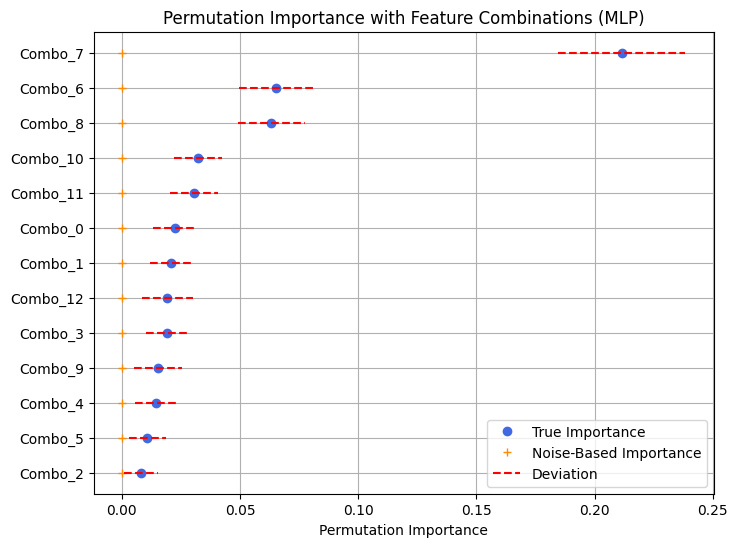

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import PolynomialFeatures

# 1 Generate Synthetic Dataset
X, y = make_classification(n_samples=1000, n_features=13, random_state=42)

# 2 Split into Train and Test Sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3 Train MLP Classifier
mlp = MLPClassifier(random_state=1, max_iter=300)
mlp.fit(X_train, y_train)

# 4 Predict on Test Set
y_pred = mlp.predict(X_test)

# 5 Evaluate Model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))
print("AUC Score:", roc_auc_score(y_test, mlp.predict_proba(X_test)[:, 1]))

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Compute Permutation Importance for Feature Combinations
r_comb = permutation_importance(mlp, X_test, y_test, scoring='accuracy', n_repeats=30, random_state=0)
feature_importances_comb = r_comb.importances_mean

# Sort indices by importance
sorted_idx = np.argsort(feature_importances_comb)

# Plot Matching Scikit-Learn's Graph Style
fig, ax = plt.subplots(figsize=(8, 6))

# True Feature Importance (Blue Dots)
ax.plot(
    feature_importances_comb[sorted_idx],  # X-values
    np.arange(len(sorted_idx)),  # Y-values
    "o",  # Blue circle markers
    color="royalblue",
    label="True Importance"
)

# Noise-Based Importance (Orange Plus Symbols)
ax.plot(
    np.zeros(len(sorted_idx)),  # Noise baseline at x=0
    np.arange(len(sorted_idx)),  # Y-values
    "+",
    color="darkorange",
    label="Noise-Based Importance"
)

# Error Bars (Red Dashes)
ax.hlines(
    y=np.arange(len(sorted_idx)),  # Y-values
    xmin=feature_importances_comb[sorted_idx] - r_comb.importances_std[sorted_idx],  # Lower bound
    xmax=feature_importances_comb[sorted_idx] + r_comb.importances_std[sorted_idx],  # Upper bound
    color="red",
    linestyle="dashed",
    label="Deviation"
)

# Y-axis Labels (Feature Combinations)
ax.set_yticks(np.arange(len(sorted_idx)))
ax.set_yticklabels([f'Combo_{i}' for i in sorted_idx])

# Labels and Title
ax.set_xlabel("Permutation Importance")
ax.set_title("Permutation Importance with Feature Combinations (MLP)")

# Grid and Legend
ax.grid(True)
ax.legend()






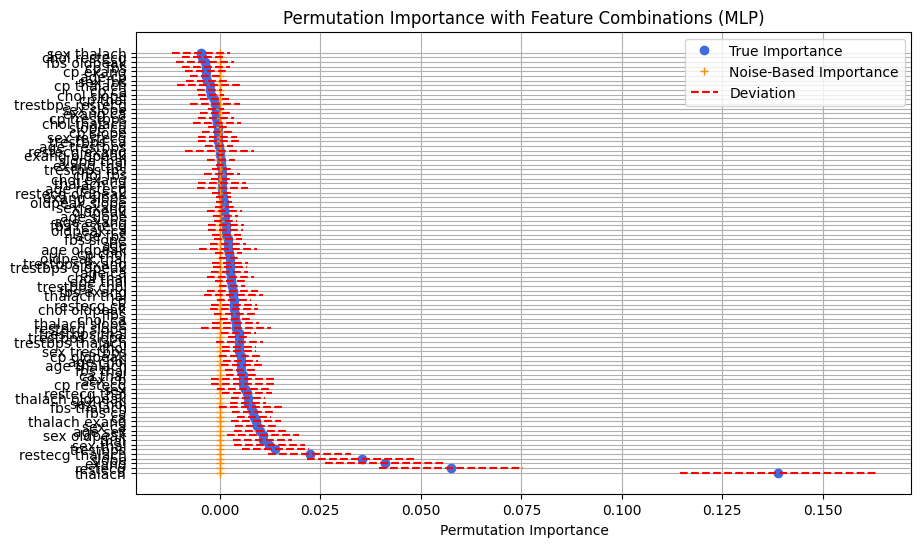

NameError: name 'pd' is not defined

In [ ]:
# List of your original feature names (from the dataset you mentioned)
feature_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
    'exang', 'oldpeak', 'slope', 'ca', 'thal'
]

# 3. Generate Interaction Terms (Feature Combinations)
poly = PolynomialFeatures(interaction_only=True, include_bias=False)
X_train_comb = poly.fit_transform(X_train)
X_test_comb = poly.transform(X_test)

# 4. Train MLP Classifier on the new feature combinations
mlp_comb = MLPClassifier(random_state=1, max_iter=300)
mlp_comb.fit(X_train_comb, y_train)

# 5. Compute Permutation Importance for the feature combinations
r_comb = permutation_importance(mlp_comb, X_test_comb, y_test, scoring='accuracy', n_repeats=30, random_state=0)
feature_importances_comb = r_comb.importances_mean

# 6. Sort indices by importance
sorted_idx_comb = np.argsort(feature_importances_comb)[::-1]  # Reverse to get most important first

# 7. Get the feature names for the combinations
interaction_feature_names = poly.get_feature_names_out(input_features=feature_names)

# 8. Sort and get the names of the combinations for the most important features
sorted_interaction_names = [interaction_feature_names[i] for i in sorted_idx_comb]

# 9. Plot the permutation importance for feature combinations
fig, ax = plt.subplots(figsize=(10, 6))

# True Feature Importance (Blue Dots)
ax.plot(
    feature_importances_comb[sorted_idx_comb],  # X-values
    np.arange(len(sorted_idx_comb)),  # Y-values
    "o",  # Blue circle markers
    color="royalblue",
    label="True Importance"
)

# Noise-Based Importance (Orange Plus Symbols)
ax.plot(
    np.zeros(len(sorted_idx_comb)),  # Noise baseline at x=0
    np.arange(len(sorted_idx_comb)),  # Y-values
    "+",
    color="darkorange",
    label="Noise-Based Importance"
)

# Error Bars (Red Dashes)
ax.hlines(
    y=np.arange(len(sorted_idx_comb)),  # Y-values
    xmin=feature_importances_comb[sorted_idx_comb] - r_comb.importances_std[sorted_idx_comb],  # Lower bound
    xmax=feature_importances_comb[sorted_idx_comb] + r_comb.importances_std[sorted_idx_comb],  # Upper bound
    color="red",
    linestyle="dashed",
    label="Deviation"
)

# Y-axis Labels (Feature Combinations)
ax.set_yticks(np.arange(len(sorted_idx_comb)))
ax.set_yticklabels(sorted_interaction_names)

# Labels and Title
ax.set_xlabel("Permutation Importance")
ax.set_title("Permutation Importance with Feature Combinations (MLP)")

# Grid and Legend
ax.grid(True)
ax.legend()

# Show the plot
plt.show()

# Print out the feature importances in order
feature_importance_comb_df = pd.DataFrame({
    'Feature Combination': sorted_interaction_names,
    'Importance': feature_importances_comb[sorted_idx_comb]
})

print("\nPermutation Feature Importances with Feature Combinations (MLP):\n")
print(feature_importance_comb_df)


Mean Absolute Error (MAE): 0.1200


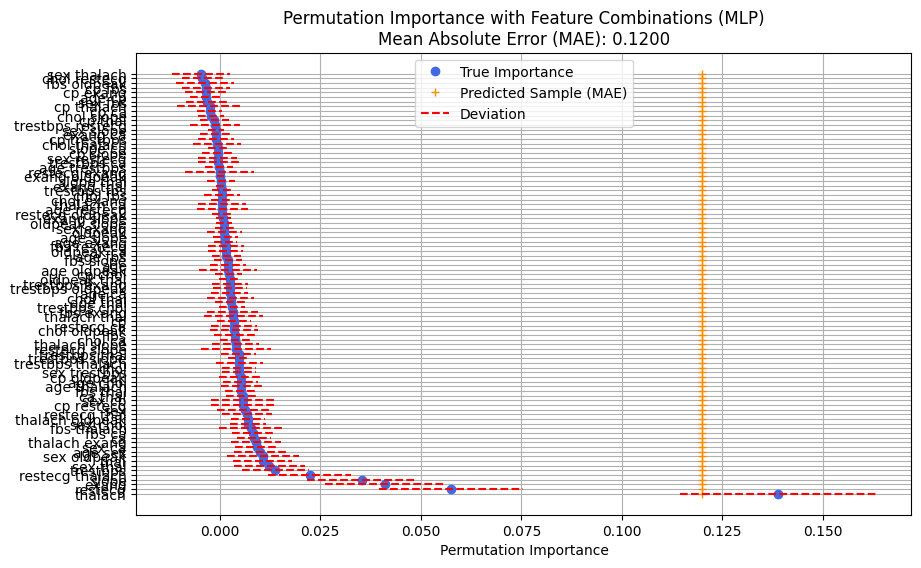

NameError: name 'pd' is not defined

In [ ]:
# List of original feature names
feature_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
    'exang', 'oldpeak', 'slope', 'ca', 'thal'
]

# 1. Generate Synthetic Dataset
X, y = make_classification(n_samples=1000, n_features=13, random_state=42)

# 2. Split into Train and Test Sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Generate Interaction Terms (Feature Combinations)
poly = PolynomialFeatures(interaction_only=True, include_bias=False)
X_train_comb = poly.fit_transform(X_train)
X_test_comb = poly.transform(X_test)

# 4. Train MLP Classifier on the new feature combinations
mlp_comb = MLPClassifier(random_state=1, max_iter=300)
mlp_comb.fit(X_train_comb, y_train)

# 5. Predict on Test Set
y_pred = mlp_comb.predict(X_test_comb)

# 6. Compute Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test, y_pred)
print(f"\nMean Absolute Error (MAE): {mae:.4f}")

# 7. Compute Permutation Importance for the feature combinations
r_comb = permutation_importance(mlp_comb, X_test_comb, y_test, scoring='accuracy', n_repeats=30, random_state=0)
feature_importances_comb = r_comb.importances_mean

# 8. Sort indices by importance
sorted_idx_comb = np.argsort(feature_importances_comb)[::-1]  # Reverse to get most important first

# 9. Get the feature names for the combinations
interaction_feature_names = poly.get_feature_names_out(input_features=feature_names)

# 10. Sort and get the names of the combinations for the most important features
sorted_interaction_names = [interaction_feature_names[i] for i in sorted_idx_comb]

# 11. Plot the permutation importance for feature combinations
fig, ax = plt.subplots(figsize=(10, 6))

# True Feature Importance (Blue Dots)
ax.plot(
    feature_importances_comb[sorted_idx_comb],  # X-values
    np.arange(len(sorted_idx_comb)),  # Y-values
    "o",  # Blue circle markers
    color="royalblue",
    label="True Importance"
)

# Predicted Sample Values (Orange Plus Symbols)
ax.plot(
    np.full(len(sorted_idx_comb), mae),  # Set all predicted values to MAE
    np.arange(len(sorted_idx_comb)),  # Y-values
    "+",
    color="darkorange",
    label="Predicted Sample (MAE)"
)

# Error Bars (Red Dashes)
ax.hlines(
    y=np.arange(len(sorted_idx_comb)),  # Y-values
    xmin=feature_importances_comb[sorted_idx_comb] - r_comb.importances_std[sorted_idx_comb],  # Lower bound
    xmax=feature_importances_comb[sorted_idx_comb] + r_comb.importances_std[sorted_idx_comb],  # Upper bound
    color="red",
    linestyle="dashed",
    label="Deviation"
)

# Y-axis Labels (Feature Combinations)
ax.set_yticks(np.arange(len(sorted_idx_comb)))
ax.set_yticklabels(sorted_interaction_names)

# Labels and Title
ax.set_xlabel("Permutation Importance")
ax.set_title("Permutation Importance with Feature Combinations (MLP)\nMean Absolute Error (MAE): {:.4f}".format(mae))

# Grid and Legend
ax.grid(True)
ax.legend()

# Show the plot
plt.show()

# Print out the feature importances in order
feature_importance_comb_df = pd.DataFrame({
    'Feature Combination': sorted_interaction_names,
    'Importance': feature_importances_comb[sorted_idx_comb]
})

print("\nPermutation Feature Importances with Feature Combinations (MLP):\n")
print(feature_importance_comb_df)

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE  # pip install imbalanced-learn if needed

# Assume you have your data loaded in variables X and y (for example, from a CSV)
# For demonstration, X and y should be defined here:
# X, y = your_data_features, your_data_labels

# Split data into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Use SMOTE to augment the training data if classes are imbalanced.
smote = SMOTE(random_state=1)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)


# Build a deeper Keras model with dropout layers.
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.1),  # 20% dropout for regularization.
    Dense(64, activation='relu'),
    Dropout(0.1),
    Dense(1, activation='sigmoid')  # For binary classification.
])

# Compile the model.
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Set up early stopping to prevent overfitting.
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the model using the augmented data.
history = model.fit(
    X_train_resampled,
    y_train_resampled,
    epochs=150,            # Increase the number of epochs.
    batch_size=32,
    validation_split=0.05,  # Use 20% of the (augmented) training data as validation.
    callbacks=[early_stop]
)

# Predict on the test set.
# The model outputs probabilities, so we convert them to class labels using a threshold of 0.5.
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype("int32").flatten()

# Evaluate the model's performance.
acc = accuracy_score(y_test, y_pred)
print("Accuracy is:", acc)

f1 = f1_score(y_test, y_pred, average='weighted')
print("F1 score is:", f1)

print("AUC Score:", roc_auc_score(y_test, mlp.predict_proba(X_test)[:, 1]))

print("\nClassification report:\n", classification_report(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))


Epoch 1/150


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step - accuracy: 0.5692 - loss: 0.6653 - val_accuracy: 0.8780 - val_loss: 0.5062
Epoch 2/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8003 - loss: 0.4989 - val_accuracy: 0.9268 - val_loss: 0.3830
Epoch 3/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8246 - loss: 0.4061 - val_accuracy: 0.9024 - val_loss: 0.3453
Epoch 4/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8408 - loss: 0.3714 - val_accuracy: 0.9024 - val_loss: 0.3351
Epoch 5/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8553 - loss: 0.3421 - val_accuracy: 0.9024 - val_loss: 0.3182
Epoch 6/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8610 - loss: 0.3300 - val_accuracy: 0.9024 - val_loss: 0.3077
Epoch 7/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8566 - loss: 0.3308 - val_accuracy: 0.9024 - val_loss: 0.3057
Epoch 8/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8626 - loss: 0.3194 - val_accuracy: 0.9024 - val_lo